In [6]:
# Force GPU runtime

#!git clone https://github.com/rapidsai/rapidsai-csp-utils.git
#!python rapidsai-csp-utils/colab/pip-install.py

In [7]:
!nvidia-smi

Sat Nov 14 00:32:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P0             26W /   70W |     105MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [8]:
%load_ext cuml.accel

The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel


In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV, ElasticNet, ElasticNetCV, LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, classification_report, roc_auc_score, roc_curve, accuracy_score, average_precision_score, silhouette_score, precision_score, recall_score, f1_score
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

from scipy.cluster.hierarchy import linkage, dendrogram

from geopy.distance import geodesic

### Import data Google Colab

In [10]:
from google.colab import drive
drive.mount('/content/drive')

train_dt = pd.read_csv("/content/drive/MyDrive/DX799_01/fraudTrain.csv", sep=",")
test_dt = pd.read_csv("/content/drive/MyDrive/DX799_01/fraudTest.csv", sep=",")

print("Training:", train_dt.shape)
print("Testing:", test_dt.shape)


Mounted at /content/drive
Training: (1296675, 23)
Testing: (555719, 23)


### Import data via VS code

In [11]:

#train_dt = pd.read_csv(r"C:\Users\marti\OneDrive\Boston University Classes\DX799 - DS Capstone - Fall 2026\Datasets for capstone\fraudTrain.csv", sep=",")

#test_dt = pd.read_csv(r"C:\Users\marti\OneDrive\Boston University Classes\DX799 - DS Capstone - Fall 2026\Datasets for capstone\fraudTest.csv", sep=",")

#df = pd.concat((train_dt, test_dt), axis=0)



## EDA

In [12]:
train_dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [13]:
train_dt.shape

(1296675, 23)

In [14]:
train_dt.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [15]:
train_dt["is_fraud"].value_counts()

,count
is_fraud,
0,1289169
1,7506


In [16]:
# Gets percentage rather than numbers above
train_dt["is_fraud"].value_counts(normalize = True) * 100

,proportion
is_fraud,
0,99.421135
1,0.578865


<Axes: xlabel='is_fraud'>

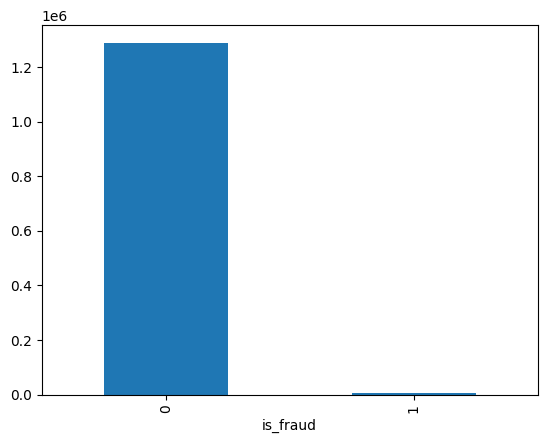

In [17]:
train_dt["is_fraud"].value_counts().plot(kind="bar")

In [18]:
train_dt.isnull().sum()

,0
Unnamed: 0,0
trans_date_trans_time,0
cc_num,0
merchant,0
category,0
amt,0
first,0
last,0
gender,0
street,0


In [19]:
train_dt.duplicated().sum()

np.int64(0)

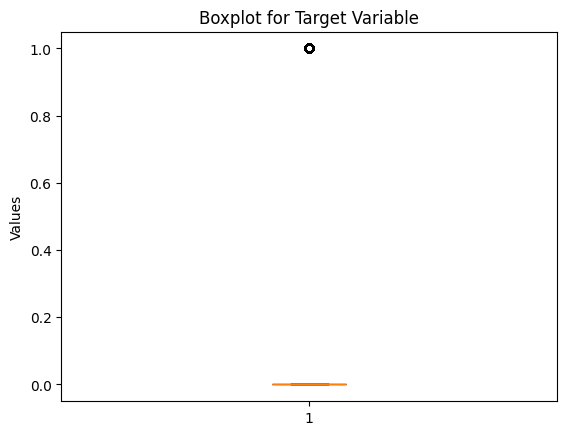

In [20]:
plt.boxplot(train_dt["is_fraud"], vert = True, patch_artist = True)
plt.title("Boxplot for Target Variable")
plt.ylabel("Values")
plt.show()

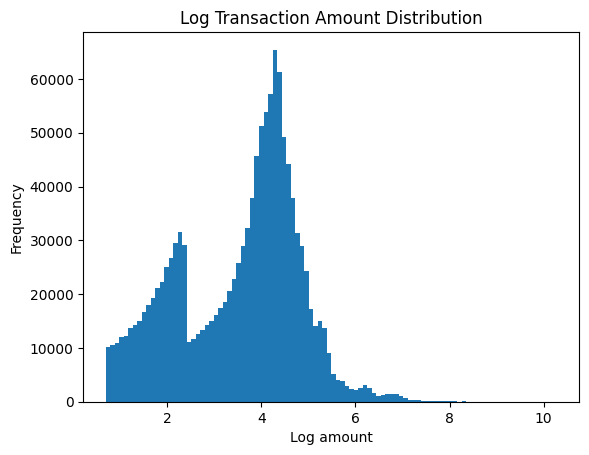

In [21]:
plt.hist(np.log1p(train_dt["amt"]), bins=100)
plt.title("Log Transaction Amount Distribution")
plt.xlabel("Log amount")
plt.ylabel("Frequency")
plt.show()


### Feature Engineering

In [22]:
# function

def feature_engineering(df):

  df = df.copy()

  # Transaction hour - fraud spikes at certain times?
  df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
  df["hour"] = df["trans_date_trans_time"].dt.hour
  df["day_of_week"] = df["trans_date_trans_time"].dt.dayofweek
  df["month"] = df["trans_date_trans_time"].dt.month


  # Distance - Large purchases that are far away from the customer may increase the chance it's fraud.
  # (Client lives in NY but transaction in TX)

  df["distance"] = df.apply(
      lambda row:geodesic(
          (row["lat"], row["long"]),
          (row["merch_lat"], row["merch_long"])
      ).miles,
      axis=1
  )


  df["dob"] = pd.to_datetime(df["dob"])

  df["age"] = (
      df["trans_date_trans_time"].dt.year - df["dob"].dt.year - (
          df["trans_date_trans_time"].dt.strftime("%m%d") < df["dob"].dt.strftime("%m%d")).astype(int)
  )

  return df


In [23]:
train_dt = feature_engineering(train_dt)
test_dt = feature_engineering(test_dt)

print("Training:", train_dt.shape)
print("Testing:", test_dt.shape)

Training: (1296675, 28)
Testing: (555719, 28)


In [24]:
X_train = train_dt.drop(columns = "is_fraud")
y_train = train_dt["is_fraud"]

X_test = test_dt.drop(columns = ["is_fraud"])
y_test = test_dt["is_fraud"]

In [25]:
encode = ["category", "state", "gender"]

drop_cols = [ "Unnamed: 0", "merchant", "first", "last", "street", "city", "job", "trans_num", "cc_num", "trans_date_trans_time", "dob", "zip", "unix_time"]

X_train = X_train.drop(columns = drop_cols)
X_test = X_test.drop(columns = drop_cols)

In [26]:
train_dt["hour"].describe()

,hour
count,1.296675e+06
mean,1.280486e+01
std,6.817824e+00
min,0.000000e+00
25%,7.000000e+00
50%,1.400000e+01
75%,1.900000e+01
max,2.300000e+01


In [27]:
train_dt["trans_date_trans_time"].describe()

,trans_date_trans_time
count,1296675
mean,2019-10-03 12:47:28.070214144
min,2019-01-01 00:00:18
25%,2019-06-03 19:12:22.500000
50%,2019-10-03 07:35:47
75%,2020-01-28 15:02:55.500000
max,2020-06-21 12:13:37


In [28]:
train_dt["dob"].describe()

,dob
count,1296675
mean,1973-10-03 19:02:55.017178512
min,1924-10-30 00:00:00
25%,1962-08-13 00:00:00
50%,1975-11-30 00:00:00
75%,1987-02-22 00:00:00
max,2005-01-29 00:00:00


In [29]:
train_dt["age"].describe()

,age
count,1.296675e+06
mean,4.549688e+01
std,1.739702e+01
min,1.300000e+01
25%,3.200000e+01
50%,4.300000e+01
75%,5.700000e+01
max,9.500000e+01


In [30]:
# Discover imbalances
train_dt.groupby("is_fraud")["amt"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.667110,154.007971,1.00,9.6100,47.280,82.540,28948.90
1,7506.0,531.320092,390.560070,1.06,245.6625,396.505,900.875,1376.04


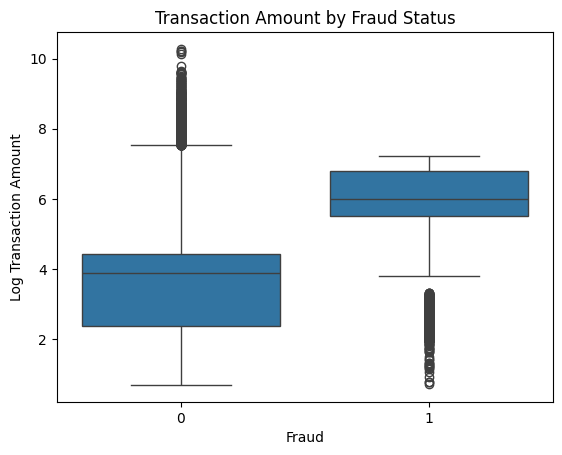

In [31]:
sns.boxplot(
    data = train_dt,
    x = "is_fraud",
    y = np.log1p(train_dt["amt"]))
plt.xlabel("Fraud")
plt.ylabel("Log Transaction Amount")
plt.title("Transaction Amount by Fraud Status")
plt.show()

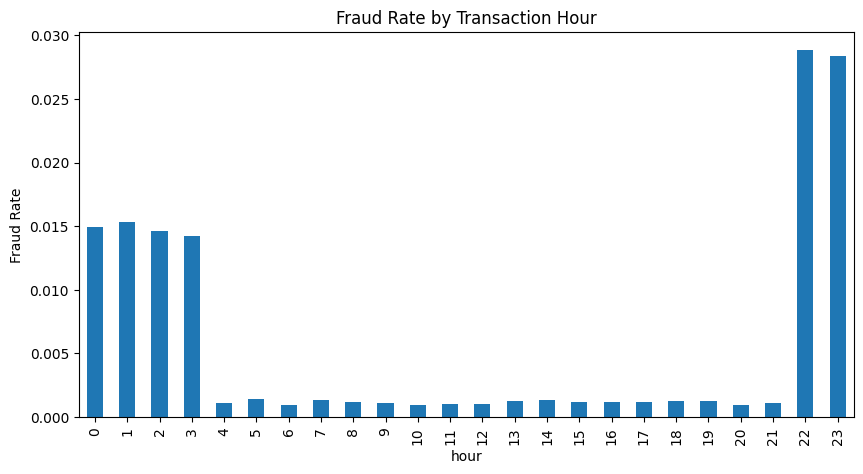

In [32]:
fraud_by_hour = train_dt.groupby("hour")["is_fraud"].mean()

fraud_by_hour.plot(
    kind = "bar",
    figsize = (10,5)
)
plt.ylabel("Fraud Rate")
plt.title("Fraud Rate by Transaction Hour")
plt.show()

In [33]:
train_dt.groupby("is_fraud")["distance"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,47.293545,18.078679,0.013840,34.396533,48.631526,61.185872,94.366525
1,7506.0,47.389826,17.851263,0.458464,34.586610,48.469498,61.108179,89.698594


## Week 8: K-Nearest Neighbors

Using a Train, Validation, and Testing sets

In [34]:
#X_train, X_test, y_train, y_test = train_test_split(
#    X,
#    y,
#    test_size = 0.2,
#    random_state = 42,
#    stratify = y)
# Don't need anymore as I did not combine data

X_train = pd.get_dummies(
    X_train,
    columns = encode,
    drop_first = False,
    dtype = int
)

X_test = pd.get_dummies(
    X_test,
    columns = encode,
    drop_first = False,
    dtype = int
)

X_test = X_test.reindex(
    columns = X_train.columns,
    fill_value = 0
)

print("Remaining Categrocial Columns:")
print(X_train.select_dtypes(include = ["object", "category"]).columns.tolist())

X_train = X_train.astype(float)
X_test = X_test.astype(float)

Remaining Categrocial Columns:
[]


In [35]:
X_train.columns.tolist()

['amt',
 'lat',
 'long',
 'city_pop',
 'merch_lat',
 'merch_long',
 'hour',
 'day_of_week',
 'month',
 'distance',
 'age',
 'category_entertainment',
 'category_food_dining',
 'category_gas_transport',
 'category_grocery_net',
 'category_grocery_pos',
 'category_health_fitness',
 'category_home',
 'category_kids_pets',
 'category_misc_net',
 'category_misc_pos',
 'category_personal_care',
 'category_shopping_net',
 'category_shopping_pos',
 'category_travel',
 'state_AK',
 'state_AL',
 'state_AR',
 'state_AZ',
 'state_CA',
 'state_CO',
 'state_CT',
 'state_DC',
 'state_DE',
 'state_FL',
 'state_GA',
 'state_HI',
 'state_IA',
 'state_ID',
 'state_IL',
 'state_IN',
 'state_KS',
 'state_KY',
 'state_LA',
 'state_MA',
 'state_MD',
 'state_ME',
 'state_MI',
 'state_MN',
 'state_MO',
 'state_MS',
 'state_MT',
 'state_NC',
 'state_ND',
 'state_NE',
 'state_NH',
 'state_NJ',
 'state_NM',
 'state_NV',
 'state_NY',
 'state_OH',
 'state_OK',
 'state_OR',
 'state_PA',
 'state_RI',
 'state_SC',
 's

In [36]:
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nDuplicate Columns")
print(X_train.columns[X_train.columns.duplicated()].tolist())

print("\nMissing Values:")
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

print("\nFraud Distribution:")
print(y_train.value_counts(normalize = True) * 100)

Training Shape: (1296675, 78)
Testing Shape: (555719, 78)

Duplicate Columns
[]

Missing Values:
0
0

Fraud Distribution:
is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


### KNN models

In [37]:
# Training set

X_sample, _, y_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size = 100000,
    random_state = 42,
    stratify = y_train
)

print("Sample Shape:", X_sample.shape)
print("\nFraud Distributions:")
print(y_sample.value_counts())

Sample Shape: (100000, 78)

Fraud Distributions:
is_fraud
0    99421
1      579
Name: count, dtype: int64


In [38]:
# Validation set

X_fit, X_val, y_fit, y_val = train_test_split(
    X_sample,
    y_sample,
    test_size = 0.2,
    random_state = 42,
    stratify = y_sample
)

print("Training:", X_fit.shape)
print("Validation:", X_val.shape)

Training: (80000, 78)
Validation: (20000, 78)


#### Baseline KNN Model

In [39]:
knn_base = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors = 5,
        metric = "euclidean"
    )
)

knn_base.fit(X_fit, y_fit)

y_pred = knn_base.predict(X_val)
y_prob = knn_base.predict_proba(X_val)[:, 1]

# predictions
print("KNN Fraud transactions - Euclidean (K = 5)")
print("Accuracy:", accuracy_score(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

print("\nAverage Precision:")
print(average_precision_score(y_val, y_prob))

KNN Fraud transactions - Euclidean (K = 5)
Accuracy: 0.99395

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     19884
           1       0.33      0.04      0.08       116

    accuracy                           0.99     20000
   macro avg       0.66      0.52      0.54     20000
weighted avg       0.99      0.99      0.99     20000


Confusion Matrix:
[[19874    10]
 [  111     5]]

Average Precision:
0.13168936451314572


In [40]:
def test_knn_fraud(X_train, y_train, k_values):

    metrics = {
        "Euclidean": {"metric": "euclidean"},
        "Manhattan": {"metric": "manhattan"},
        "Cosine": {"metric": "cosine"},
        "Minkowski": {"metric": "minkowski", "p": 3}
    }

    results = []

    cv = StratifiedKFold(
        n_splits = 3,
        shuffle = True,
        random_state = 42
    )

    for metric_name, params in metrics.items():
        for k in k_values:

            model = make_pipeline(
                StandardScaler(),
                KNeighborsClassifier(
                    n_neighbors = k,
                    **params
                )
            )

            scores = cross_val_score(
                model,
                X_train,
                y_train,
                cv = cv,
                scoring = "average_precision",
                n_jobs = 1
            )

            results.append({
                "Metric": metric_name,
                "K": k,
                "CV Average Precision": scores.mean(),
                "CV Std": scores.std()
            })

            print(
                f"{metric_name} | K = {k} | "
                f"Average Precision= {scores.mean():.4f}"
            )
    results_df = pd.DataFrame(results)

    return results_df.sort_values(
        by = "CV Average Precision",
        ascending = False
    ).reset_index(drop = True)

Below runs a small set of data

In [41]:
k_values = [3, 5, 9]

fraud_results = test_knn_fraud(X_sample, y_sample, k_values)

print(fraud_results)

Euclidean | K = 3 | Average Precision= 0.1642
Euclidean | K = 5 | Average Precision= 0.1598
Euclidean | K = 9 | Average Precision= 0.1566
Manhattan | K = 3 | Average Precision= 0.1490
Manhattan | K = 5 | Average Precision= 0.1537
Manhattan | K = 9 | Average Precision= 0.1455
Cosine | K = 3 | Average Precision= 0.1617
Cosine | K = 5 | Average Precision= 0.1639
Cosine | K = 9 | Average Precision= 0.1596
Minkowski | K = 3 | Average Precision= 0.1641
Minkowski | K = 5 | Average Precision= 0.1578
Minkowski | K = 9 | Average Precision= 0.1497
       Metric  K  CV Average Precision    CV Std
0   Euclidean  3              0.164211  0.013220
1   Minkowski  3              0.164067  0.009303
2      Cosine  5              0.163863  0.008192
3      Cosine  3              0.161737  0.004791
4   Euclidean  5              0.159807  0.008671
5      Cosine  9              0.159621  0.017211
6   Minkowski  5              0.157828  0.009071
7   Euclidean  9              0.156567  0.014836
8   Manhattan  5

### Final KNN Evaluation on test data uing optimal K

In [42]:
best_knn_fraud = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors = 3,
        metric = "euclidean",
        n_jobs = 1
    )
)

# train on full training data
best_knn_fraud.fit(X_train, y_train)

# predict using full data

y_pred_best = best_knn_fraud.predict(X_test)
y_prob_best = best_knn_fraud.predict_proba(X_test)[:, 1]

# perfomance metrics
print("Optimized KNN Fraud Transactions - Euclidean (k=3)")
print("Accuracy:", accuracy_score(y_test, y_pred_best))

print("\nAverage Precision:")
print(average_precision_score(y_test, y_prob_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

Optimized KNN Fraud Transactions - Euclidean (k=3)
Accuracy: 0.997097453929054

Average Precision:
0.3477442173032407

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.76      0.36      0.49      2145

    accuracy                           1.00    555719
   macro avg       0.88      0.68      0.74    555719
weighted avg       1.00      1.00      1.00    555719


Confusion Matrix:
[[553332    242]
 [  1371    774]]


## Week 9: Gradient Boost

In [43]:
gb_base = HistGradientBoostingClassifier(random_state = 42)

gb_base.fit(X_train, y_train)
y_pred = gb_base.predict(X_test)
y_prob = gb_base.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(f"\nROC AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print(f"\nAverage Precision: {average_precision_score(y_test, y_prob):.4f}")

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.83      0.77      0.80      2145

    accuracy                           1.00    555719
   macro avg       0.92      0.88      0.90    555719
weighted avg       1.00      1.00      1.00    555719


Confusion Matrix:
[[553239    335]
 [   496   1649]]

ROC AUC Score: 0.9514

Average Precision: 0.7626


#### Test different learning Rates

In [44]:
learning_rates = [0.01, 0.05, 0.1, 0.2]
lr_results = []

cv = StratifiedKFold(
    n_splits = 3,
    shuffle = True,
    random_state = 42
)

for lr in learning_rates:
    gb_model = HistGradientBoostingClassifier(
        learning_rate = lr,
        max_iter = 100,
        early_stopping = False,
        random_state = 42
    )

    scores = cross_val_score(
        gb_model,
        X_train,
        y_train,
        cv = cv,
        scoring = "average_precision",
        n_jobs = -1
    )

    lr_results.append({
        "Learning Rate": lr,
        "Mean Average Precision": scores.mean(),
        "Std Average Precision": scores.std()
    })

lr_results_df = pd.DataFrame(lr_results)

display(lr_results_df.round(4))

best_lr = lr_results_df.loc[
    lr_results_df["Mean Average Precision"].idxmax(),
    "Learning Rate"
]

print(f"Best Learning Rate: {best_lr}")

,Learning Rate,Mean Average Precision,Std Average Precision
0,0.01,0.8977,0.0084
1,0.05,0.8668,0.0344
2,0.10,0.4255,0.0753
3,0.20,0.2137,0.0072


Best Learning Rate: 0.01


### Testing max iterations

In [45]:
max_iter_list = [50, 100, 150, 200, 300]
n_results = []

for n in max_iter_list:
    gb_model = HistGradientBoostingClassifier(
        learning_rate = best_lr,
        max_iter = n,
        early_stopping = False,
        random_state = 42
    )

    scores = cross_val_score(
        gb_model,
        X_train,
        y_train,
        cv = cv,
        scoring = "average_precision",
        n_jobs = -1
    )

    n_results.append({
        "Max Iterations": n,
        "Mean Average Precision": scores.mean(),
        "Std Average Precision": scores.std()
    })

n_results_df = pd.DataFrame(n_results)
display(n_results_df.round(4))

best_n = n_results_df.loc[
    n_results_df["Mean Average Precision"].idxmax(),
    "Max Iterations"]

print(f"Best Number of Iterations: {best_n}")

,Max Iterations,Mean Average Precision,Std Average Precision
0,50,0.8805,0.0086
1,100,0.8977,0.0084
2,150,0.9075,0.0027
3,200,0.9128,0.0025
4,300,0.9195,0.0028


Best Number of Iterations: 300


### Tuning max_depth

In [46]:
tree_depths = [1, 2, 3, 4, 5]
depth_results = []

for depth in tree_depths:
    gb_model = HistGradientBoostingClassifier(
        learning_rate = best_lr,
        max_iter = best_n,
        max_depth = depth,
        early_stopping = False,
        random_state = 42
    )

    scores = cross_val_score(
        gb_model,
        X_train,
        y_train,
        cv = cv,
        scoring = "average_precision",
        n_jobs = -1
    )

    depth_results.append({
        "Max Depth": depth,
        "Mean Average Precision": scores.mean(),
        "Std Average Precision": scores.std()
    })

depth_results_df = pd.DataFrame(depth_results)
display(depth_results_df.round(4))

best_depth = depth_results_df.loc[
    depth_results_df["Mean Average Precision"].idxmax(),
    "Max Depth"]

print(f"Max Depth: {best_depth}")

,Max Depth,Mean Average Precision,Std Average Precision
0,1,0.5052,0.0133
1,2,0.6786,0.0106
2,3,0.7993,0.0040
3,4,0.8500,0.0047
4,5,0.8768,0.0030


Max Depth: 5


### Tune L2 regularizaton

In [47]:
l2_values = [0.0, 0.1, 1.0, 10.0]
l2_results = []

for l2 in l2_values:
    gb_model = HistGradientBoostingClassifier(
        learning_rate = best_lr,
        max_iter = best_n,
        max_depth = best_depth,
        l2_regularization = l2,
        early_stopping = False,
        random_state = 42
    )

    scores = cross_val_score(
        gb_model,
        X_train,
        y_train,
        cv = cv,
        scoring = "average_precision",
        n_jobs = -1
    )

    l2_results.append({
        "L2 Regularization": l2,
        "Mean Average Precision": scores.mean(),
        "Std Average Precision": scores.std()
    })

l2_results_df = pd.DataFrame(l2_results)
display(l2_results_df.round(4))

best_l2 = l2_results_df.loc[
    l2_results_df["Mean Average Precision"].idxmax(),
    "L2 Regularization"]

print(f" Best L2 Regularization: {best_l2}")

,L2 Regularization,Mean Average Precision,Std Average Precision
0,0.0,0.8768,0.0030
1,0.1,0.8752,0.0033
2,1.0,0.8698,0.0030
3,10.0,0.8571,0.0046


 Best L2 Regularization: 0.0


### Final Model

In [48]:
gb_final = HistGradientBoostingClassifier(
    learning_rate = best_lr,
    max_iter = best_n,
    max_depth = best_depth,
    l2_regularization = best_l2,
    early_stopping = False,
    random_state = 42
)

gb_final.fit(X_train, y_train)

y_pred = gb_final.predict(X_test)
y_prob = gb_final.predict_proba(X_test)[:, 1]

print("Final Gradient Boosting Model")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(f"\nROC AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print(f"\nAverage Precision: {average_precision_score(y_test, y_prob):.4f}")

Final Gradient Boosting Model

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.91      0.68      0.78      2145

    accuracy                           1.00    555719
   macro avg       0.95      0.84      0.89    555719
weighted avg       1.00      1.00      1.00    555719


Confusion Matrix:
[[553424    150]
 [   683   1462]]

ROC AUC Score: 0.9929

Average Precision: 0.8320


## Week 10: Clustering 1

In [50]:
features = ["amt", "lat", "long", "city_pop", "merch_lat", "merch_long"]

X = train_dt[features].copy()
y = train_dt["is_fraud"].copy()

print("Selected Features:")
print(X.columns.tolist())

print("\nMissing Values:")
print(X.isnull().sum())


Selected Features:
['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long']

Missing Values:
amt           0
lat           0
long          0
city_pop      0
merch_lat     0
merch_long    0
dtype: int64


In [51]:
df_sample = train_dt.sample(n = 20000, random_state = 42)

X = df_sample[features].copy()
y = df_sample["is_fraud"].copy()

print("\nFraud Distribution:")
print(y.value_counts())


Fraud Distribution:
is_fraud
0    19881
1      119
Name: count, dtype: int64


### Feature Scaling

In [52]:
## Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(
    X_scaled,
    columns = X.columns,
    index = X.index
)

display(X_scaled.head())

,amt,lat,long,city_pop,merch_lat,merch_long
1045211,0.909476,0.415736,0.787361,-0.283785,0.374645,0.829968
547406,-0.125871,0.852385,-2.492165,-0.286231,0.833794,-2.430075
110142,-0.459287,0.286957,0.763246,-0.286338,0.385387,0.827552
1285953,-0.453462,0.878666,0.943820,-0.252208,1.031842,0.999091
271705,-0.038712,0.618677,-1.016406,-0.284877,0.496371,-1.006969


### Elbow Method

,K,Inertia
0,2,110110.94
1,3,82551.43
2,4,61619.91
3,5,56236.90
4,6,43020.84
5,7,41174.12
6,8,36623.07
7,9,34363.82
8,10,33459.39


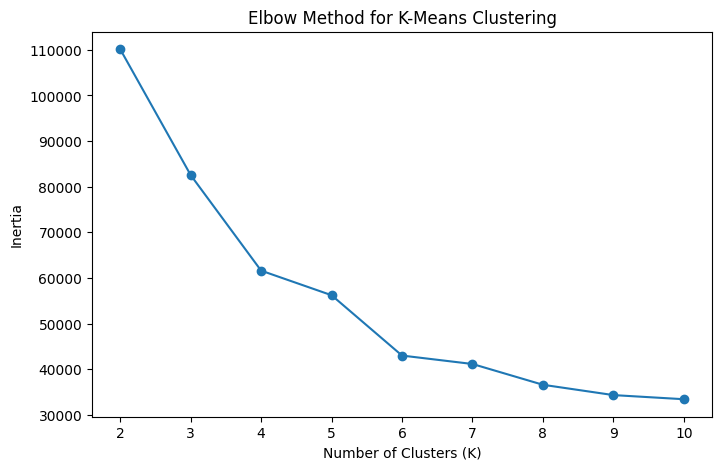

In [53]:
## Elbow method

inertia = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

inertia_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia
})

display(inertia_df.round(2))

plt.figure(figsize = (8, 5))
plt.plot(k_values, inertia, marker = "o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(k_values)
plt.show()

### Silhoutette Method

,K,Silhouette Score
0,2,0.6393
1,3,0.3230
2,4,0.3725
3,5,0.3798
4,6,0.3739
5,7,0.4004
6,8,0.3476
7,9,0.3571
8,10,0.3589


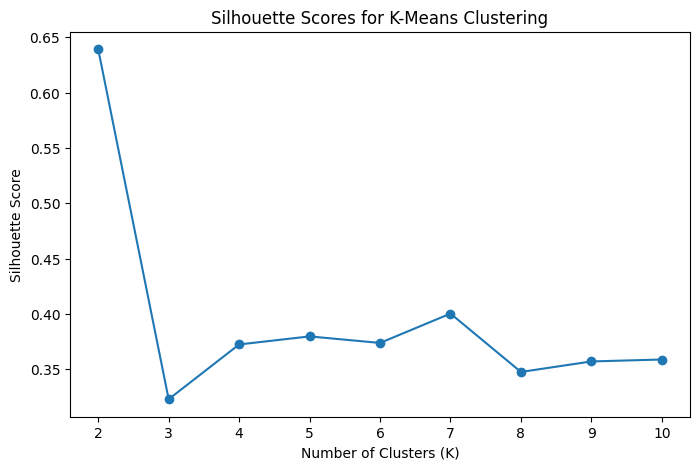

In [54]:
## Silhoutette

silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size = 5000,
        random_state = 42
    )

    silhouette_scores.append(score)

silhouette_df = pd.DataFrame({
    "K": list(k_values),
    "Silhouette Score": silhouette_scores
})
display(silhouette_df.round(4))

plt.figure(figsize = (8, 5))
plt.plot(k_values, silhouette_scores, marker = "o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for K-Means Clustering")
plt.xticks(k_values)
plt.show()

#### Comparing k = 4 and k = 5

In [55]:
for k in [4, 5]:
    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    labels = kmeans.fit_predict(X_scaled)
    cluster_counts = pd.Series(labels).value_counts().sort_index()

    print(f"\nK = {k}")
    print(f"Inertia: {kmeans.inertia_:.4f}")
    print("\nCluster Sizes:")
    print(cluster_counts)


K = 4
Inertia: 61619.9142

Cluster Sizes:
0     6185
1       34
2     3455
3    10326
Name: count, dtype: int64

K = 5
Inertia: 56236.8977

Cluster Sizes:
0     3423
1       10
2    10197
3      257
4     6113
Name: count, dtype: int64


### Examine clusters

In [56]:
best_k = 4

kmeans_final = KMeans(
    n_clusters = best_k,
    random_state = 42,
    n_init = 10
)
labels = kmeans_final.fit_predict(X_scaled)
df_sample["Cluster"] = labels

cluster_summary = df_sample.groupby("Cluster").agg(
    Transactions = ("is_fraud", "count"),
    Fraud_Count = ("is_fraud", "sum"),
    Fraud_Rate = ("is_fraud", "mean"),
    Average_Amount = ("amt", "mean"),
    Average_City_Pop = ("city_pop", "mean")
)

cluster_summary["Fraud_Rate"] = cluster_summary["Fraud_Rate"] * 100 # percentage

display(cluster_summary.round(4))

,Transactions,Fraud_Count,Fraud_Rate,Average_Amount,Average_City_Pop
Cluster,,,,,
0,6185,31,0.5012,66.0995,143286.4935
1,34,0,0.0000,2223.7859,95562.0000
2,3455,18,0.5210,67.3778,77626.7384
3,10326,70,0.6779,65.3599,59398.2234


#### Distance Metrics

In [57]:
## Distance Calculation

def calculate_distance(x1, x2):

    euclidean = np.sqrt(np.sum((x1 - x2) ** 2))
    manhattan = np.sum(np.abs(x1 - x2))

    return euclidean, manhattan

In [58]:
### Compare transactions

distance_results = []

for i in range(1, 10):

    euclidean, manhattan = calculate_distance(
        X_scaled.iloc[0], X_scaled.iloc[i]
    )

    distance_results.append({
        "Transaction": i,
        "Euclidean Distance": euclidean,
        "Manhattan Distance": manhattan
    })

distance_df = pd.DataFrame(distance_results)
display(distance_df.round(4))

,Transaction,Euclidean Distance,Manhattan Distance
0,1,4.7809,8.4732
1,2,1.3751,1.5374
2,3,1.5993,2.8402
3,4,2.7537,4.9147
4,5,1.3192,2.8809
5,6,2.3513,4.0644
6,7,2.9410,6.4185
7,8,3.1844,7.1217
8,9,2.5141,5.1323


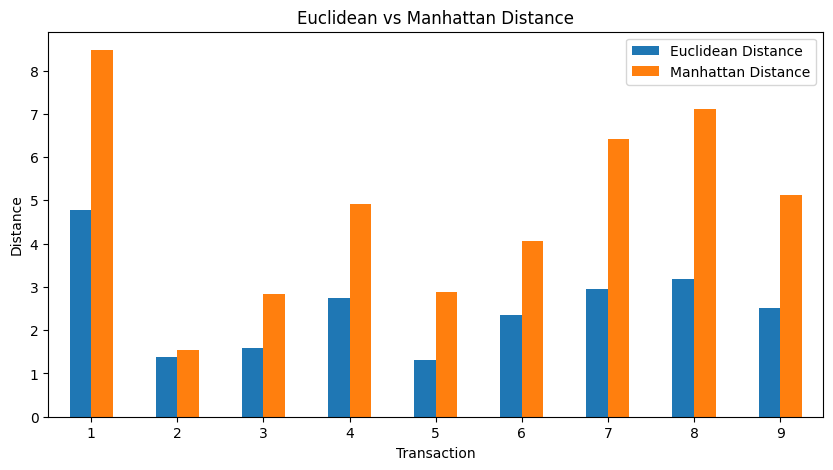

In [59]:
distance_df.plot(
    x = "Transaction",
    y = ["Euclidean Distance", "Manhattan Distance"],
    kind = "bar",
    figsize = (10, 5)
)

plt.ylabel("Distance")
plt.title("Euclidean vs Manhattan Distance")
plt.xticks(rotation = 0)
plt.show()

### Final Evaluation

In [60]:
final_inertia = kmeans_final.inertia_

final_silhouette = silhouette_score(
    X_scaled,
    labels,
    sample_size = 5000,
    random_state = 42
)

print(f"Final Number of Clusters: {best_k}")
print(f"Final Inertia: {final_inertia:.4f}")
print(f"Final Silhoutte Score: {final_silhouette:.4f}")

Final Number of Clusters: 4
Final Inertia: 61619.9142
Final Silhoutte Score: 0.3725


### Examining Cluster Centroids

In [61]:
centroids = scaler.inverse_transform(kmeans_final.cluster_centers_)

centroid_df = pd.DataFrame(
    centroids,
    columns = X.columns
)
centroid_df.index.name = "Cluster"

display(centroid_df.round(4))

,amt,lat,long,city_pop,merch_lat,merch_long
Cluster,,,,,,
0,65.9754,32.7195,-90.3870,143907.2583,32.7024,-90.3948
1,2223.7859,36.1880,-93.3496,95562.0000,36.1152,-93.2824
2,67.3965,40.8918,-113.3562,76748.1669,40.9017,-113.3817
3,65.4288,41.1877,-82.4491,59366.3509,41.1967,-82.4521


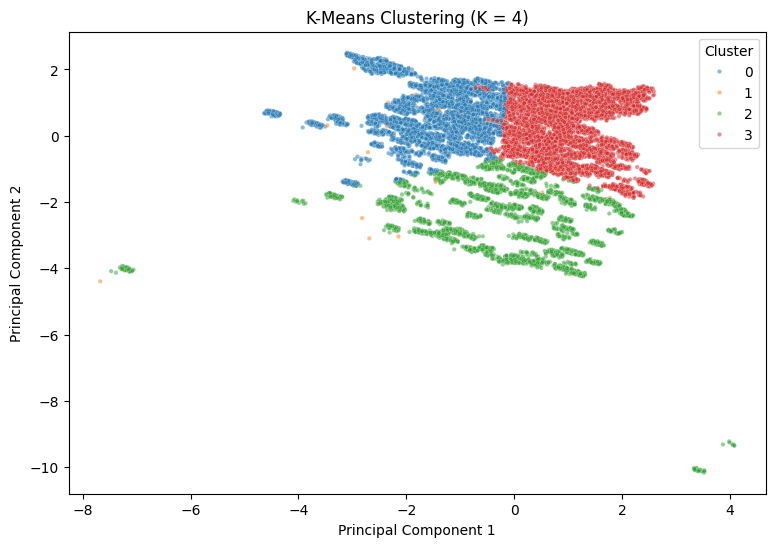

Explained Variance Ratio: [0.34282739 0.33272043]
Total Explained Variance: 0.6755


In [62]:
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize = (9, 6))

sns.scatterplot(
    x = X_pca[:, 0],
    y = X_pca[:, 1],
    hue = labels,
    palette = "tab10",
    alpha = 0.5,
    s = 10
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering (K = 4)")
plt.legend(title = "Cluster")
plt.show()

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print(f"Total Explained Variance: {pca.explained_variance_ratio_.sum():.4f}")


## Week 11: Clustering: part 2

In [122]:
cluster_features = ["amt", "lat", "long", "city_pop", "merch_lat", "merch_long"]

X_cluster = X_train[cluster_features].copy()
y_cluster = y_train.loc[X_cluster.index].copy()

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_cluster),
    columns = X_cluster.columns,
    index = X_cluster.index
)

X_dbscan = X_scaled.sample(
    n = 5000,
    random_state = 42
).copy()

y_dbscan = y_cluster.loc[X_dbscan.index].copy()

print("DBSCAN Data Schape:", X_dbscan.shape)
print("Fraud Distribution:")
print(y_dbscan.value_counts())

DBSCAN Data Schape: (5000, 6)
Fraud Distribution:
is_fraud
0    4969
1      31
Name: count, dtype: int64


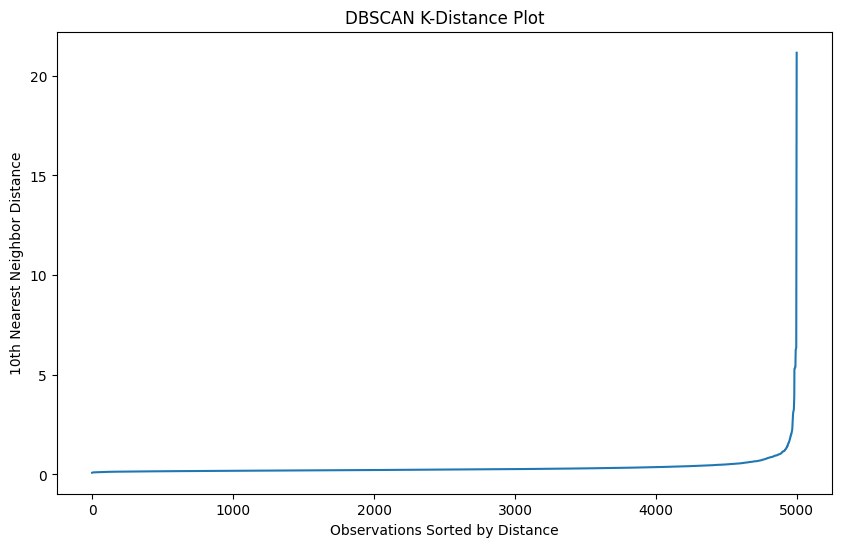

In [123]:
min_samples = 10
neighbors = NearestNeighbors(n_neighbors = min_samples)
neighbors.fit(X_dbscan)

distances, indices = neighbors.kneighbors(X_dbscan)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize = (10, 6))
plt.plot(k_distances)
plt.xlabel("Observations Sorted by Distance")
plt.ylabel("10th Nearest Neighbor Distance")
plt.title("DBSCAN K-Distance Plot")
plt.show()

In [124]:
dbscan_1 = DBSCAN(
    eps = 1.0,
    min_samples = 10
)

dbscan_labels = dbscan_1.fit_predict(X_dbscan)

dbscan_results = X_dbscan.copy()
dbscan_results["Cluster"] = dbscan_labels
dbscan_results["is_fraud"] = y_dbscan.loc[X_dbscan.index]

print("DBSCAN Cluster Distribution:")
print(dbscan_results["Cluster"].value_counts().sort_index())

n_clusters = len(set(dbscan_labels) - {-1})
n_noise = np.sum(dbscan_labels == -1)

print("\nNumber of clusters:", n_clusters)
print("Number of Noise Points:", n_noise)
print("Noise Percentage:", round(n_noise / len(dbscan_labels) * 100, 2), "%")

DBSCAN Cluster Distribution:
Cluster
-1      87
 0    4798
 1      21
 2      22
 3      18
 4      18
 5      13
 6      11
 7      12
Name: count, dtype: int64

Number of clusters: 8
Number of Noise Points: 87
Noise Percentage: 1.74 %


In [125]:
# Examine rates by cluster
cluster_summary = dbscan_results.groupby("Cluster").agg(
    Transactions = ("is_fraud", "count"),
    Fraud_Count = ("is_fraud", "sum"),
    Fraud_Rate = ("is_fraud", "mean")
)

cluster_summary["Fraud_Rate"] = cluster_summary["Fraud_Rate"] * 100
display(cluster_summary.round(4))

,Transactions,Fraud_Count,Fraud_Rate
Cluster,,,
-1,87,15,17.2414
0,4798,15,0.3126
1,21,0,0.0000
2,22,0,0.0000
3,18,0,0.0000
4,18,1,5.5556
5,13,0,0.0000
6,11,0,0.0000
7,12,0,0.0000


In [126]:
# Calucalte fraud decision metrics
y_true = dbscan_results["is_fraud"]
y_pred = (dbscan_results["Cluster"] == -1).astype(int)

print("Precision:", round(precision_score(y_true, y_pred), 4))
print("Recall:", round(recall_score(y_true, y_pred), 4))
print("F1-Score:", round(f1_score(y_true, y_pred), 4))

Precision: 0.1724
Recall: 0.4839
F1-Score: 0.2542


In [127]:
# Dbscan parameter tuning

eps_values = [0.5, 0.75, 1.0, 1.25, 1.5]
min_samples_values = [5, 10, 15]

dbscan_tuning = []

for eps in eps_values:
  for min_samples in min_samples_values:

    model = DBSCAN(
        eps = eps,
        min_samples = min_samples
    )

    labels = model.fit_predict(X_dbscan)
    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    fraud_noise = np.sum(
        (labels == -1) & (y_dbscan.to_numpy() == 1)
    )

    noise_fraud_rate = (
        fraud_noise / n_noise * 100
        if n_noise > 0 else 0
    )

    dbscan_tuning.append({
        "eps": eps,
        "min_samples": min_samples,
        "Clusters": n_clusters,
        "Noise": n_noise,
        "Noise %": n_noise / len(labels) * 100,
        "Fraud in Noise": fraud_noise,
        "Noise Fraud Rate in %": noise_fraud_rate,
        "Fraud Recall in %": fraud_noise / y_dbscan.sum() * 100
    })

dbscan_tuning_df = pd.DataFrame(dbscan_tuning)
display(dbscan_tuning_df.round(4))

,eps,min_samples,Clusters,Noise,Noise %,Fraud in Noise,Noise Fraud Rate in %,Fraud Recall in %
0,0.50,5,30,178,3.56,20,11.2360,64.5161
1,0.50,10,15,328,6.56,23,7.0122,74.1935
2,0.50,15,8,468,9.36,25,5.3419,80.6452
3,0.75,5,18,84,1.68,13,15.4762,41.9355
4,0.75,10,10,164,3.28,17,10.3659,54.8387
5,0.75,15,8,200,4.00,17,8.5000,54.8387
6,1.00,5,11,40,0.80,10,25.0000,32.2581
7,1.00,10,8,87,1.74,15,17.2414,48.3871
8,1.00,15,5,132,2.64,15,11.3636,48.3871
9,1.25,5,10,28,0.56,7,25.0000,22.5806


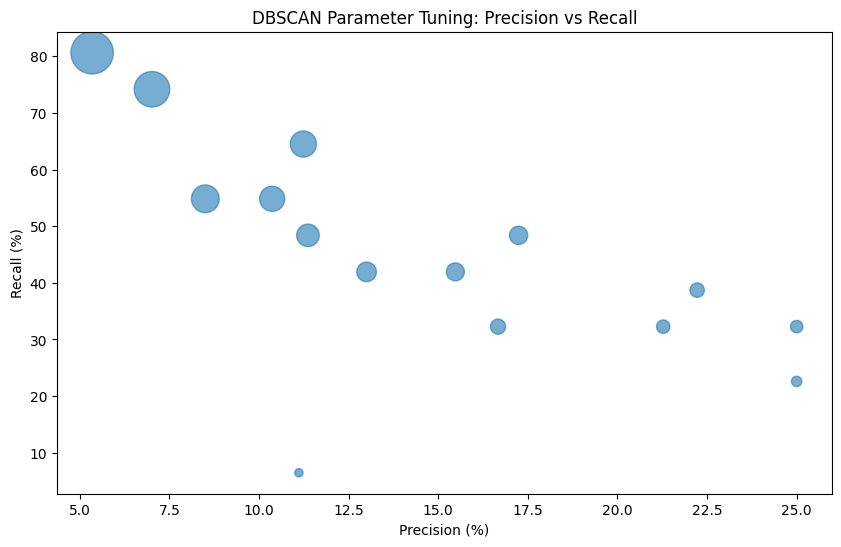

In [128]:
# Graph the above

plt.figure(figsize = (10, 6))
plt.scatter(
    dbscan_tuning_df["Noise Fraud Rate in %"],
    dbscan_tuning_df["Fraud Recall in %"],
    s = dbscan_tuning_df["Noise"] * 2,
    alpha = 0.6
)

plt.xlabel("Precision (%)")
plt.ylabel("Recall (%)")
plt.title("DBSCAN Parameter Tuning: Precision vs Recall")
plt.show()

In [141]:
# run silhouette score
mask = dbscan_labels != -1

if len(np.unique(dbscan_labels[mask])) >= 2:
  score = silhouette_score(
      X_dbscan.loc[mask],
      dbscan_labels[mask]
  )

  print("DBSCAN Silhouette Score:", round(score, 4))
else:
  print("Silhouette score can't be calculated")

DBSCAN Silhouette Score: 0.4059


In [142]:
# HAC Data Prep

X_hac = X_dbscan.sample(
    n = 1000,
    random_state = 42
).copy()

y_hac = y_dbscan.loc[X_hac.index].copy()

print("HAC Data Shape:", X_hac.shape)
print("\nFraud Distribution:")
print(y_hac.value_counts())

HAC Data Shape: (1000, 6)

Fraud Distribution:
is_fraud
0    993
1      7
Name: count, dtype: int64


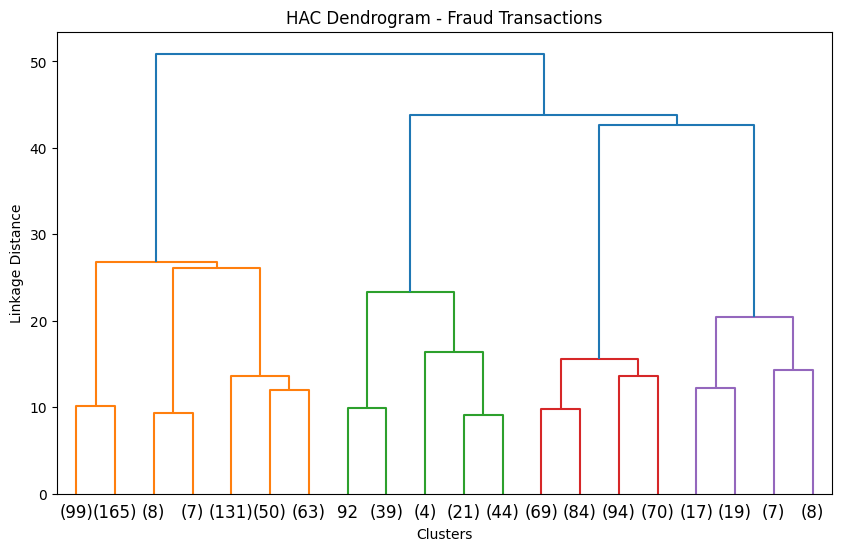

In [143]:
linked = linkage(X_hac, method = "ward")

plt.figure(figsize = (10, 6))

dendrogram(
    linked,
    truncate_mode = "lastp",
    p = 20,
    show_leaf_counts = True
)

plt.title("HAC Dendrogram - Fraud Transactions")
plt.xlabel("Clusters")
plt.ylabel("Linkage Distance")
plt.show()

In [144]:
# Fit the model
hac_1 = AgglomerativeClustering(
    n_clusters = 4,
    linkage = "ward"
)

hac_labels = hac_1.fit_predict(X_hac)
hac_results = X_hac.copy()
hac_results["Cluster"] = hac_labels
hac_results["is_fraud"] = y_hac.loc[X_hac.index]

print("HAC Cluster Distribution:")
print(hac_results["Cluster"].value_counts().sort_index())

HAC Cluster Distribution:
Cluster
0    523
1     51
2    109
3    317
Name: count, dtype: int64


In [145]:
hac_silhouette = silhouette_score(X_hac, hac_labels)

print("HAC Silhouette Score:", round(hac_silhouette, 4))

HAC Silhouette Score: 0.3443


In [146]:
# Examine by cluster

hac_summary = hac_results.groupby("Cluster").agg(
    Transactions = ("is_fraud", "count"),
    Fraud_Count = ("is_fraud", "sum"),
    Fraud_Rate = ("is_fraud", "mean")
)

hac_summary["Fraud_Rate"] *= 100 # multiplies itself and stores it in hac_summary["Fraud_Rate"]

display(hac_summary.round(4))

,Transactions,Fraud_Count,Fraud_Rate
Cluster,,,
0,523,4,0.7648
1,51,1,1.9608
2,109,1,0.9174
3,317,1,0.3155


In [153]:
# compare linkage methods

linkage_methods = ["ward", "complete", "average", "single"]

hac_comparison = []

for method in linkage_methods:

  hac_model = AgglomerativeClustering(
      n_clusters = 4,
      linkage = method
  )

  labels = hac_model.fit_predict(X_hac)
  score = silhouette_score(X_hac, labels)
  cluster_sizes = pd.Series(labels).value_counts()

  hac_comparison.append({
      "Linkage": method,
      "Clusters": len(np.unique(labels)),
      "Silhouette Score": score,
      "Smallest Cluster": cluster_sizes.min(),
      "Largest Cluster": cluster_sizes.max()
  })

hac_comparison_df = pd.DataFrame(hac_comparison)
display(hac_comparison_df.round(4))

,Linkage,Clusters,Silhouette Score,Smallest Cluster,Largest Cluster
0,ward,4,0.3443,51,523
1,complete,4,0.6549,1,986
2,average,4,0.5894,1,960
3,single,4,0.6541,1,988


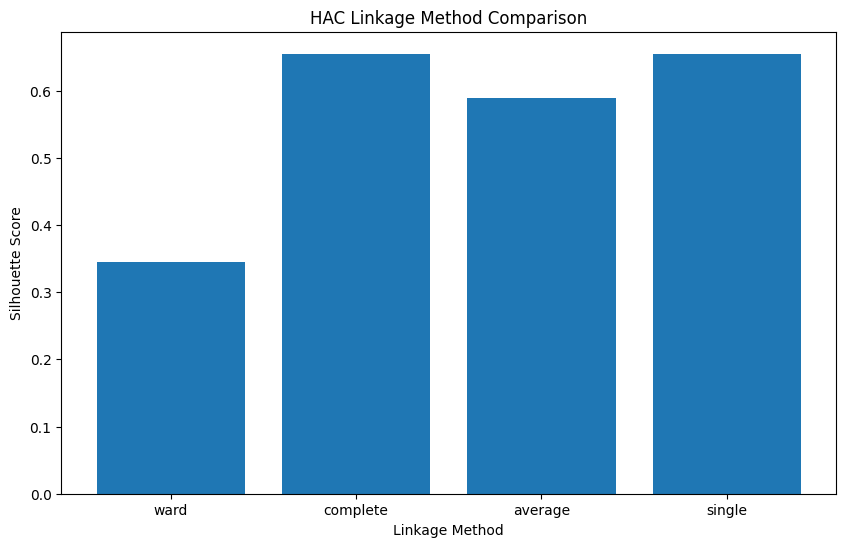

In [148]:
# visualize the comparison

plt.figure(figsize = (10, 6))
plt.bar(
    hac_comparison_df["Linkage"],
    hac_comparison_df["Silhouette Score"]
)

plt.xlabel("Linkage Method")
plt.ylabel("Silhouette Score")
plt.title("HAC Linkage Method Comparison")
plt.show()

In [149]:
## Test different HAC Clusters

hac_k_results = []

for k in range(2, 11):

  model = AgglomerativeClustering(
      n_clusters = k,
      linkage = "ward"
  )

  labels = model.fit_predict(X_hac)
  score = silhouette_score(X_hac, labels)
  sizes = pd.Series(labels).value_counts()

  hac_k_results.append({
      "Clusters": k,
      "Silhouette Score": score,
      "Smallest Cluster": sizes.min(),
      "Largest Cluster": sizes.max()
  })

hac_k_df = pd.DataFrame(hac_k_results)

display(hac_k_df.round(4))

,Clusters,Silhouette Score,Smallest Cluster,Largest Cluster
0,2,0.2887,477,523
1,3,0.3263,109,523
2,4,0.3443,51,523
3,5,0.3080,51,317
4,6,0.3204,15,317
5,7,0.3333,15,317
6,8,0.3391,15,317
7,9,0.3402,4,317
8,10,0.2999,4,264


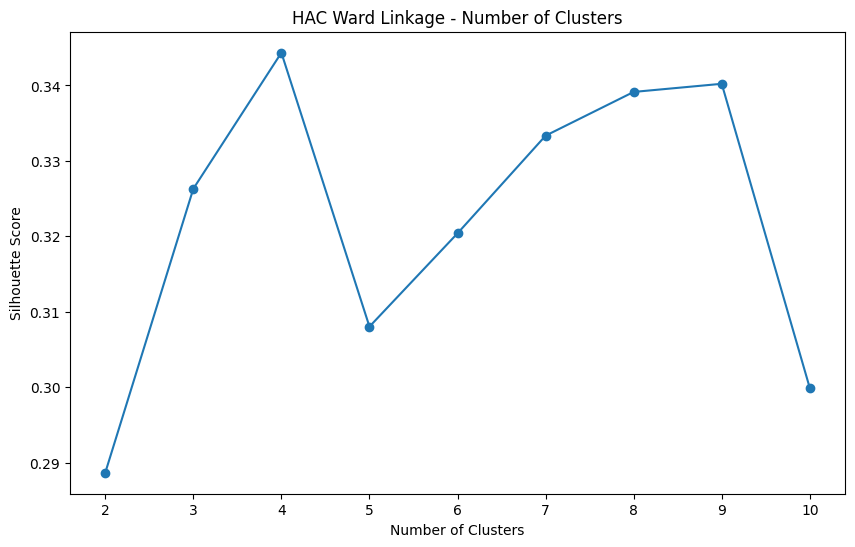

In [150]:
# visualzie it
plt.figure(figsize = (10, 6))
plt.plot(
    hac_k_df["Clusters"],
    hac_k_df["Silhouette Score"],
    marker = "o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("HAC Ward Linkage - Number of Clusters")
plt.show()

### Final DBSCAN Eval

In [151]:
## Final DBSCAN Eval
y_pred = (dbscan_labels == -1).astype(int)

print("DBSCAN Classification Report")
print(classification_report(y_dbscan, y_pred, target_names = ["Legit", "Fraud"]))


DBSCAN Classification Report
              precision    recall  f1-score   support

       Legit       1.00      0.99      0.99      4969
       Fraud       0.17      0.48      0.25        31

    accuracy                           0.98      5000
   macro avg       0.58      0.73      0.62      5000
weighted avg       0.99      0.98      0.99      5000



### Final HAC Eval

In [152]:
hac_silhouette = silhouette_score(X_hac, hac_labels)

hac_summary = hac_results.groupby("Cluster").agg(
    Transactions = ("is_fraud", "count"),
    Fraud_count = ("is_fraud", "sum"),
    Fraud_Rate = ("is_fraud", "mean")
)
hac_summary["Fraud_Rate"] *= 100

print("Final HAC Eval")
print("Silhouette Score:", round(hac_silhouette, 4))
print("Number of Clusters:", len(np.unique(hac_labels)))

display(hac_summary.round(4))

Final HAC Eval
Silhouette Score: 0.3443
Number of Clusters: 4


,Transactions,Fraud_count,Fraud_Rate
Cluster,,,
0,523,4,0.7648
1,51,1,1.9608
2,109,1,0.9174
3,317,1,0.3155
